In [62]:
import numpy as np
import pandas as pd 
from matplotlib import pyplot as plt

In [63]:
training = np.loadtxt('trainingI.dat')
validation = np.loadtxt('validationI.dat')
ranges = np.loadtxt('rangesII.dat')
checkpoints = np.loadtxt('checkpointsII.dat')
anchors = np.loadtxt('anchorsII.dat')

In [64]:
def legendre(x, n):
    P = np.zeros(n)

    P[0] = 1
    P[1] = x

    for k in range(1, n-1):
        P[k+1] = ((2*k+1)*x*P[k] - k*P[k-1])/(k+1)

    return P

In [65]:
x = training[:, 0]
b = training[:, 1]

n = 8
m = 60

A = np.zeros((m, n))

for i in range(m):
    A[i, :] = legendre(x[i], n)

In [66]:
theta_ls = np.linalg.inv(A.T @ A) @ A.T @ b


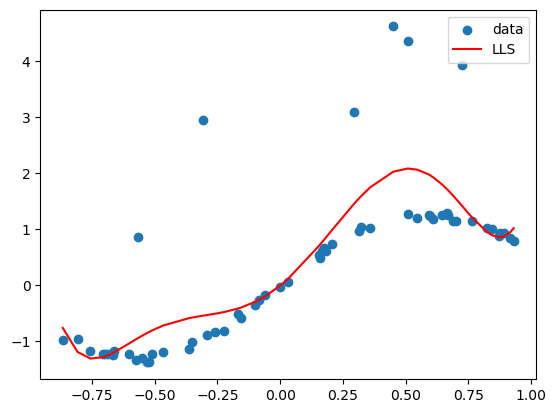

In [67]:
plt.scatter(x, b, label = 'data')
plt.plot(x, A@theta_ls, color = 'red' ,label = 'LLS')
plt.legend()

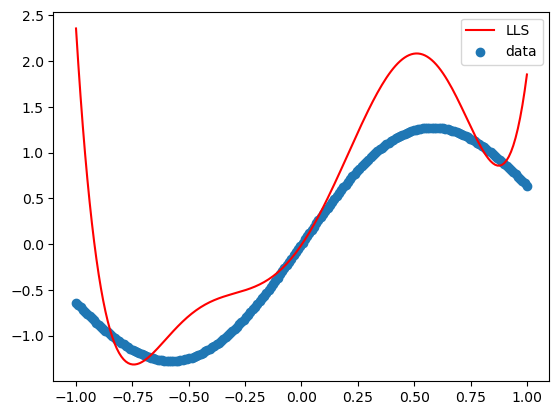

In [68]:
x2, b2 = validation[:, 0], validation[:, 1]
A2 = np.zeros((200,8))
for i in range(200):
    A2[i, :] = legendre(x2[i], n)
    
theta_2 = np.linalg.inv(A2.T @ A2) @ A2.T @ b2
plt.plot(x2, A2@theta_ls, color = 'red', label = 'LLS')
plt.scatter(x2, b2, label = 'data')
plt.legend()


In [69]:
validation_error = 0
V = A2 @ theta_2
for i in range(200):
    validation_error += (abs(V[i] - b2[i]))**2

validation_error = validation_error / 200
validation_error

np.float64(1.2063231359239371e-08)

In [70]:
residuals = A2 @ theta_2 - b2
residuals_outliers = A @ theta_ls - b

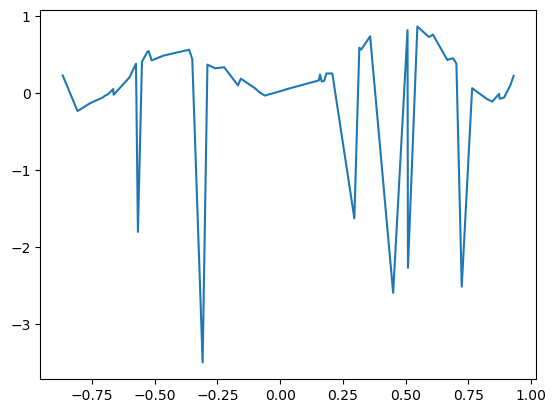

In [71]:
plt.plot(x , residuals_outliers)

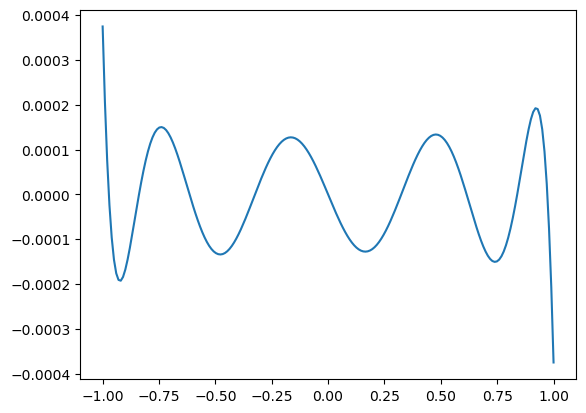

In [72]:
plt.plot(x2, residuals)

In [73]:
np.linalg.cond(A2.T@A2)

np.float64(14.210429548748612)

In [74]:
def polynomial(x, n):
    P = np.zeros(n)
    P[0] = 1
    for i in range(1, n):
        P[i] = x**i
    return P
    
        
        
        

In [75]:
A3 = np.zeros((200, 8))
for i in range(200):
    A3[i : ,] = polynomial(x2[i], n)

np.linalg.cond(A3.T@A3)

np.float64(52902.529947814524)

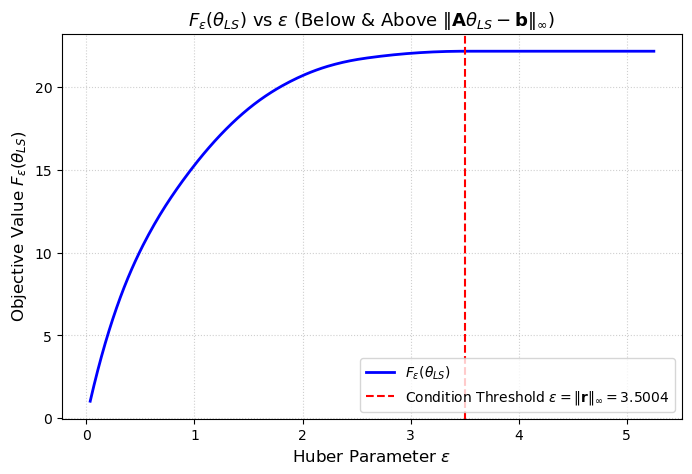

In [76]:

# 1. Define the element-wise Huber loss
def huber_loss(t, eps):
    return np.where(np.abs(t) <= eps, 0.5 * t**2, eps * (np.abs(t) - 0.5 * eps))

# 2. Residuals & max norm condition
res = A @ theta_ls - b
max_res = np.max(np.abs(res))  # ||A*theta_LS - b||_infty

# 3. Create a range of epsilon values (from slightly above 0 to max_res * 1.5)
eps_values = np.linspace(0.01 * max_res, 1.5 * max_res, 300)
f_values = []

# 4. Compute F_eps(theta_LS) for each epsilon
for eps in eps_values:
    # Sum Huber loss across all residual elements
    F_eps = np.sum(huber_loss(res, eps))
    f_values.append(F_eps)

# 5. Distance from the condition: (max_res - epsilon)
# Positive distance = epsilon is BELOW the condition (epsilon < max_res)
# Negative distance = epsilon is ABOVE the condition (epsilon > max_res)
distance_from_condition = max_res - eps_values

# --- Plotting ---
plt.figure(figsize=(8, 5))
plt.plot(eps_values, f_values, label=r'$F_\epsilon(\theta_{LS})$', color='blue', linewidth=2)

# Vertical line at the threshold epsilon = ||A*theta_LS - b||_infty
plt.axvline(x=max_res, color='red', linestyle='--', 
            label=rf'Condition Threshold $\epsilon = \|\mathbf{{r}}\|_{{\infty}} = {max_res:.4f}$')

plt.xlabel(r'Huber Parameter $\epsilon$', fontsize=12)
plt.ylabel(r'Objective Value $F_\epsilon(\theta_{LS})$', fontsize=12)
plt.title(r'$F_\epsilon(\theta_{LS})$ vs $\epsilon$ (Below & Above $\|\mathbf{A}\theta_{LS} - \mathbf{b}\|_\infty$)', fontsize=13)
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()



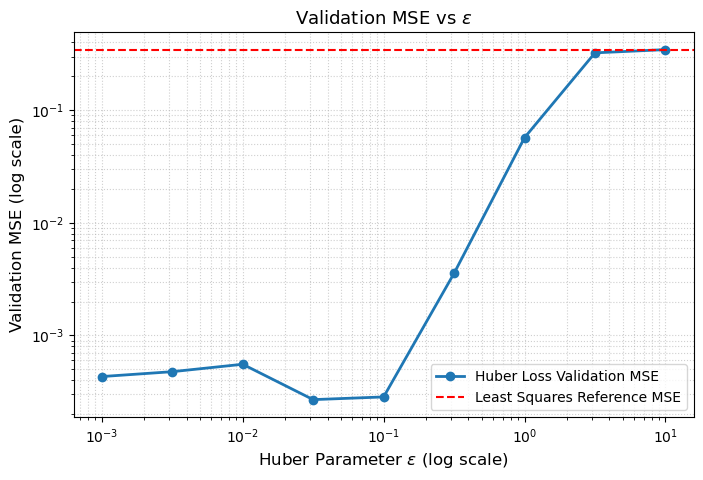

[20699, 13805, 6208, 3693, 2727, 3165, 3633, 3852, 3854]


In [82]:
import numpy as np
import matplotlib.pyplot as plt

def gradient_descent_huber(A, b, eps, stepsize, tol=1e-6, max_iter=500000):
    m, n = A.shape
    theta = np.zeros(n)
    
    for k in range(max_iter):
        residual = A @ theta - b
        # Huber gradient: A^T * clip(A*theta - b, -eps, eps)
        grad = A.T @ np.clip(residual, -eps, eps)
        
        # Stopping criterion based on gradient norm
        if np.linalg.norm(grad) <= tol:
            return theta, k + 1
        
        # Standard gradient descent update with constant stepsize t = 1 / sigma_max(A)^2
        theta = theta - stepsize * grad
        
    return theta, max_iter

# --- Run for eps = 10^-3, 10^-2.5, ..., 10^1 ---
eps_powers = np.arange(-3, 1.5, 0.5)
eps_values = 10**eps_powers

# Constant stepsize specified in the assignment
sigma_max = np.linalg.norm(A, 2)
t_step = 1.0 / (sigma_max**2)

val_mses = []
iterations = []

# Reference Least Squares Validation MSE
theta_ls = np.linalg.lstsq(A, b, rcond=None)[0]
ls_val_mse = np.mean((A2 @ theta_ls - b2)**2)
for ep in eps_values:
    theta_opt, num_iter = gradient_descent_huber(A, b, ep, stepsize=t_step, tol=1e-6)
    iterations.append(num_iter)
    
    # Calculate Validation MSE on clean validation dataset
    res_val = A2 @ theta_opt - b2
    mse_val = np.mean(res_val**2)
    val_mses.append(mse_val)
    


# --- Plot Validation MSE vs Epsilon ---
plt.figure(figsize=(8, 5))
plt.loglog(eps_values, val_mses, 'o-', label='Huber Loss Validation MSE', color='C0', linewidth=2)
plt.axhline(y=ls_val_mse, color='red', linestyle='--', label='Least Squares Reference MSE', linewidth=1.5)

plt.xlabel(r'Huber Parameter $\epsilon$ (log scale)', fontsize=12)
plt.ylabel('Validation MSE (log scale)', fontsize=12)
plt.title(r'Validation MSE vs $\epsilon$', fontsize=13)
plt.legend()
plt.grid(True, which="both", linestyle=":", alpha=0.6)
plt.show()
print(iterations)

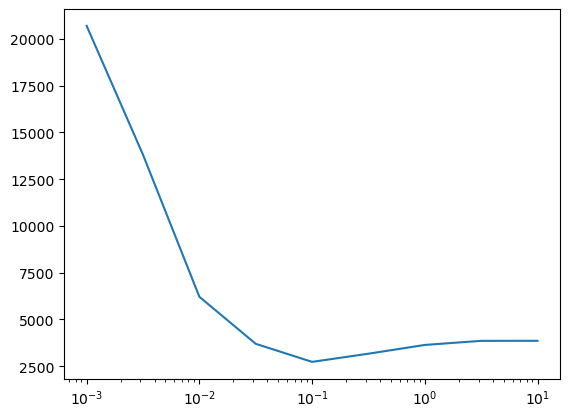

In [85]:
plt.semilogx(eps_values, iterations)

Best Epsilon: 3.1623e-02 with Validation MSE: 0.000269


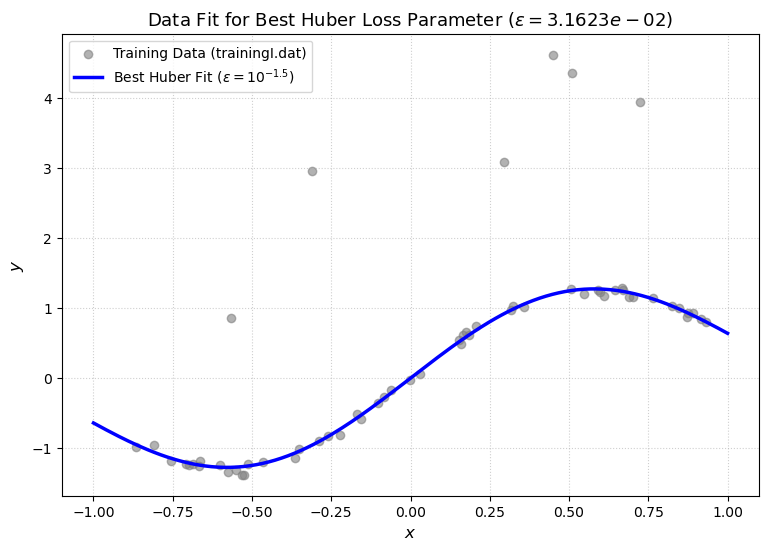

In [78]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Identify the best epsilon (lowest validation MSE)
best_idx = np.argmin(val_mses)
best_eps = eps_values[best_idx]
print(f"Best Epsilon: {best_eps:.4e} with Validation MSE: {val_mses[best_idx]:.6f}")

# 2. Re-run or extract the optimal theta for best_eps
theta_best, _ = gradient_descent_huber(A2, b2, best_eps, stepsize=t_step, tol=1e-5)

# 3. Compute fitted values for training data
# For a smooth curve plot across the input range x:

# Build matrix A_dense for plotting smooth curve
# Assuming degree n (e.g., Legendre basis or Monomial basis)
# Example for Legendre basis:

# Compute predictions
y_huber_fit = A2 @ theta_best
y_ls_fit = A @ theta_ls

# --- Plotting the Fit ---
plt.figure(figsize=(9, 6))

# Plot raw training points
plt.scatter(x, b, color='gray', alpha=0.6, label='Training Data (trainingI.dat)')

# Plot Huber fit for best epsilon
plt.plot(x2, y_huber_fit, color='blue', linewidth=2.5, 
         label=rf'Best Huber Fit ($\epsilon = 10^{{{eps_powers[best_idx]:.1f}}}$)')

# Plot Least Squares fit for comparison
# plt.plot(x, y_ls_fit, color='red', linestyle='--', linewidth=2, 
#          label='Least Squares Fit ($\ell_2$)')

plt.xlabel('$x$', fontsize=12)
plt.ylabel('$y$', fontsize=12)
plt.title(rf'Data Fit for Best Huber Loss Parameter ($\epsilon = {best_eps:.4e}$)', fontsize=13)
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

In [79]:
outliers = []
x_rest = [i for i in x if i < -0.5]
for i in range(len(x_rest)):
    if b[i] > 0:
        outliers.append(i+1)
for i,x_vals in enumerate(x):
    if b[i] > 2:
        outliers.append(i+1)
outliers

    
        

[11, 19, 36, 40, 42, 52]

In [80]:


r_t = ranges[0]  

def compute_hessian_g1(p, anchors, r_t):
    hess = np.zeros((2, 2))
    

    for i in range(3):
        diff = p - anchors[i]  
        dist_sq = np.sum(diff**2)  
        outer_term = 2 * np.outer(diff, diff)
        identity_term = (dist_sq - r_t[i]**2) * np.eye(2)
        hess += outer_term + identity_term
        
    return hess


for idx in range(3):
    p_anchor = anchors[idx]
    H = compute_hessian_g1(p_anchor, anchors, r_t)
    
    print(f"--- Hessian at Anchor s_{idx+1} ({p_anchor}) ---")
    print(H)
    


--- Hessian at Anchor s_1 ([0. 0.]) ---
[[263.69281078   4.        ]
 [  4.          14.01281078]]
--- Hessian at Anchor s_2 ([5.  0.4]) ---
[[ 38.85281078   0.        ]
 [  0.         -60.50718922]]
--- Hessian at Anchor s_3 ([10.  0.]) ---
[[263.69281078  -4.        ]
 [ -4.          14.01281078]]


eps        |I| (Inliers)   lambda_min(A_I^T A_I)    
--------------------------------------------------
1.00e-02   18              9.483307e-02             
1.00e-01   52              1.839245e-01             
1.00e+00   54              1.911875e-01             


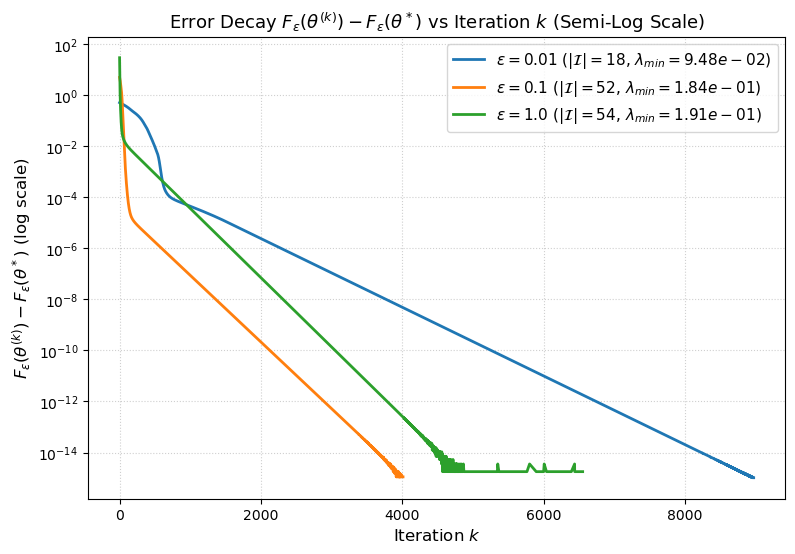

In [81]:

# 1. Huber Loss function evaluation
def huber_loss_total(A, b, theta, eps):
    r = A @ theta - b
    abs_r = np.abs(r)
    quad_mask = abs_r <= eps
    loss = np.where(quad_mask, 0.5 * r**2, eps * (abs_r - 0.5 * eps))
    return np.sum(loss)

# 2. Gradient Descent saving cost history
def gd_huber_history(A, b, eps, stepsize, tol=1e-8, max_iter=200000):
    m, n = A.shape
    theta = np.zeros(n)
    cost_history = []
    
    for k in range(max_iter):
        r = A @ theta - b
        cost_history.append(huber_loss_total(A, b, theta, eps))
        
        grad = A.T @ np.clip(r, -eps, eps)
        if np.linalg.norm(grad) <= tol:
            break
            
        theta = theta - stepsize * grad
        
    return theta, np.array(cost_history)

# Step size t = 1 / sigma_max(A)^2
sigma_max = np.linalg.norm(A, 2)
t_step = 1.0 / (sigma_max**2)

eps_target = [1e-2, 1e-1, 1.0]

plt.figure(figsize=(9, 6))

print(f"{'eps':<10} {'|I| (Inliers)':<15} {'lambda_min(A_I^T A_I)':<25}")
print("-" * 50)

for ep in eps_target:
    # Run to high precision to get optimal theta* and history
    theta_opt, history = gd_huber_history(A, b, ep, stepsize=t_step, tol=1e-10, max_iter=250000)
    
    F_star = history[-1]  # F_eps(theta*)
    
    # Compute active set I = { i : |r_i| < eps }
    r_opt = A @ theta_opt - b
    I_mask = np.abs(r_opt) < ep
    I_size = np.sum(I_mask)
    
    # Submatrix A_I formed by rows indexed by I
    A_I = A[I_mask, :]
    hessian_I = A_I.T @ A_I
    lambda_min = np.min(np.linalg.eigvalsh(hessian_I))
    
    print(f"{ep:<10.2e} {I_size:<15} {lambda_min:<25.6e}")
    
    # Compute F_eps(theta^k) - F_eps(theta*)
    error_decay = history - F_star
    
    # Filter out tiny or zero/negative differences for log plotting
    valid_k = error_decay > 1e-15
    k_axis = np.arange(len(history))[valid_k]
    decay_values = error_decay[valid_k]
    
    # Plot on semi-log scale (y-axis log, x-axis linear)
    plt.semilogy(k_axis, decay_values, label=rf'$\epsilon = {ep}$ ($|\mathcal{{I}}|={I_size}$, $\lambda_{{min}}={lambda_min:.2e}$)', linewidth=2)

plt.xlabel('Iteration $k$', fontsize=12)
plt.ylabel(r'$F_\epsilon(\theta^{(k)}) - F_\epsilon(\theta^*)$ (log scale)', fontsize=12)
plt.title(r'Error Decay $F_\epsilon(\theta^{(k)}) - F_\epsilon(\theta^*)$ vs Iteration $k$ (Semi-Log Scale)', fontsize=13)
plt.legend(fontsize=11)
plt.grid(True, which="both", linestyle=":", alpha=0.6)
plt.show()